# 02. Exploratory analysis

**Question:** which employees leave, and which factors go with a higher attrition rate?

All charts show the **attrition rate** (share of employees who left), not raw counts. The dashed line is the overall rate. Red bars are above it.

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

from hr_utils import (load_raw, load_clean, rate_table, segment_table, plot_rate, savefig, save_table,
                      SEGMENT_FACTORS, PROCESSED, ACCENT, BASE)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

In [2]:
df = load_clean()
overall = df["attrition_flag"].mean() * 100
leavers = int(df["attrition_flag"].sum())
print(f"{len(df):,} employees, {leavers:,} left. Overall attrition rate: {overall:.2f}%")

10,000 employees, 2,247 left. Overall attrition rate: 22.47%


## 1. Leavers vs stayers (averages)

In [3]:
num_cols = ["age", "salary", "distance_from_home", "environment_satisfaction", "work_life_balance",
            "job_involvement", "job_satisfaction", "years_since_promotion", "years_at_company",
            "total_experience_years", "salary_hike_pct"]
cmp = df.groupby("attrition")[num_cols].mean().T.round(2).rename(columns={"Yes": "left", "No": "stayed"})
cmp["difference"] = (cmp["left"] - cmp["stayed"]).round(2)
cmp["difference_pct"] = (100 * cmp["difference"] / cmp["stayed"]).round(1)
cmp.sort_values("difference_pct", key=abs, ascending=False)

attrition,stayed,left,difference,difference_pct
distance_from_home,24.28,29.46,5.18,21.3
environment_satisfaction,3.14,2.47,-0.67,-21.3
years_since_promotion,3.81,4.58,0.77,20.2
job_involvement,3.11,2.56,-0.55,-17.7
work_life_balance,3.12,2.61,-0.51,-16.3
job_satisfaction,3.06,2.77,-0.29,-9.5
total_experience_years,10.01,9.87,-0.14,-1.4
salary_hike_pct,50.02,50.59,0.57,1.1
age,40.54,40.35,-0.19,-0.5
salary,114409.63,114778.51,368.88,0.3


Leavers score lower on environment satisfaction, work-life balance and job involvement, live farther away, and had their last promotion longer ago. Salary, age and experience are almost the same for both groups.

## 2. Employee experience scores

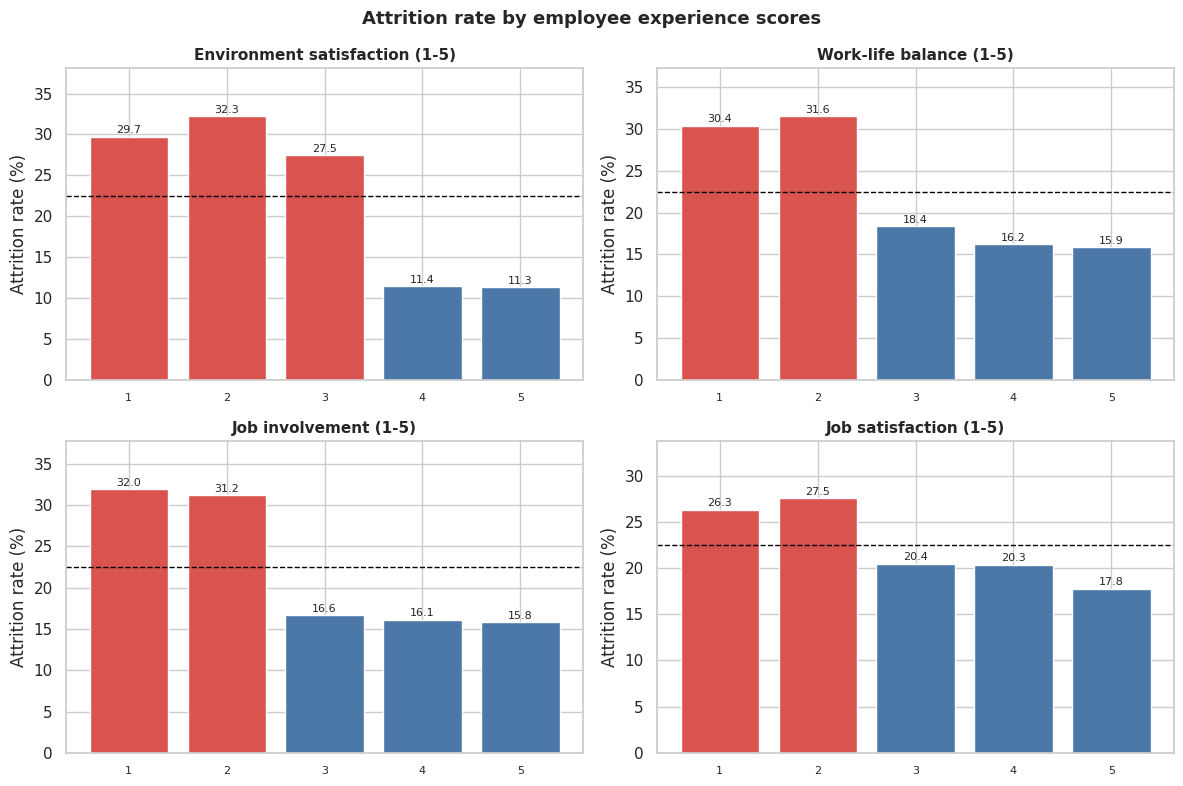

In [4]:
panels = [("environment_satisfaction", "Environment satisfaction (1-5)"),
          ("work_life_balance", "Work-life balance (1-5)"),
          ("job_involvement", "Job involvement (1-5)"),
          ("job_satisfaction", "Job satisfaction (1-5)")]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (col, title) in zip(axes.flat, panels):
    plot_rate(ax, rate_table(df, col), col, overall, title)
fig.suptitle("Attrition rate by employee experience scores", fontsize=13, fontweight="bold")
fig.tight_layout()
savefig(fig, "02_attrition_by_experience_scores")
plt.show()

## 3. Work pattern factors

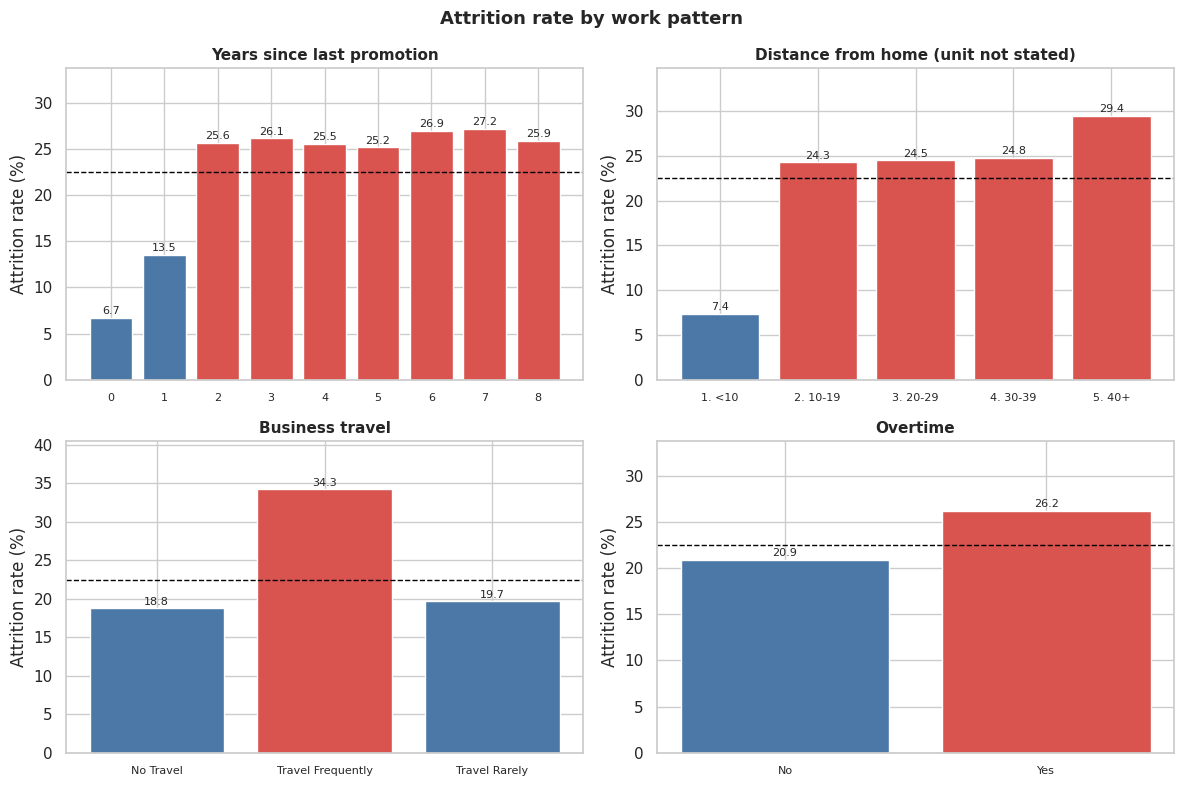

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
plot_rate(axes[0, 0], rate_table(df, "years_since_promotion"), "years_since_promotion", overall, "Years since last promotion")
plot_rate(axes[0, 1], rate_table(df, "distance_band"), "distance_band", overall, "Distance from home (unit not stated)")
plot_rate(axes[1, 0], rate_table(df, "business_travel"), "business_travel", overall, "Business travel")
plot_rate(axes[1, 1], rate_table(df, "overtime"), "overtime", overall, "Overtime")
fig.suptitle("Attrition rate by work pattern", fontsize=13, fontweight="bold")
fig.tight_layout()
savefig(fig, "02_attrition_by_work_pattern")
plt.show()

## 4. Factors with little or no effect

All panels use the same y-axis range, so the bars can be compared fairly.

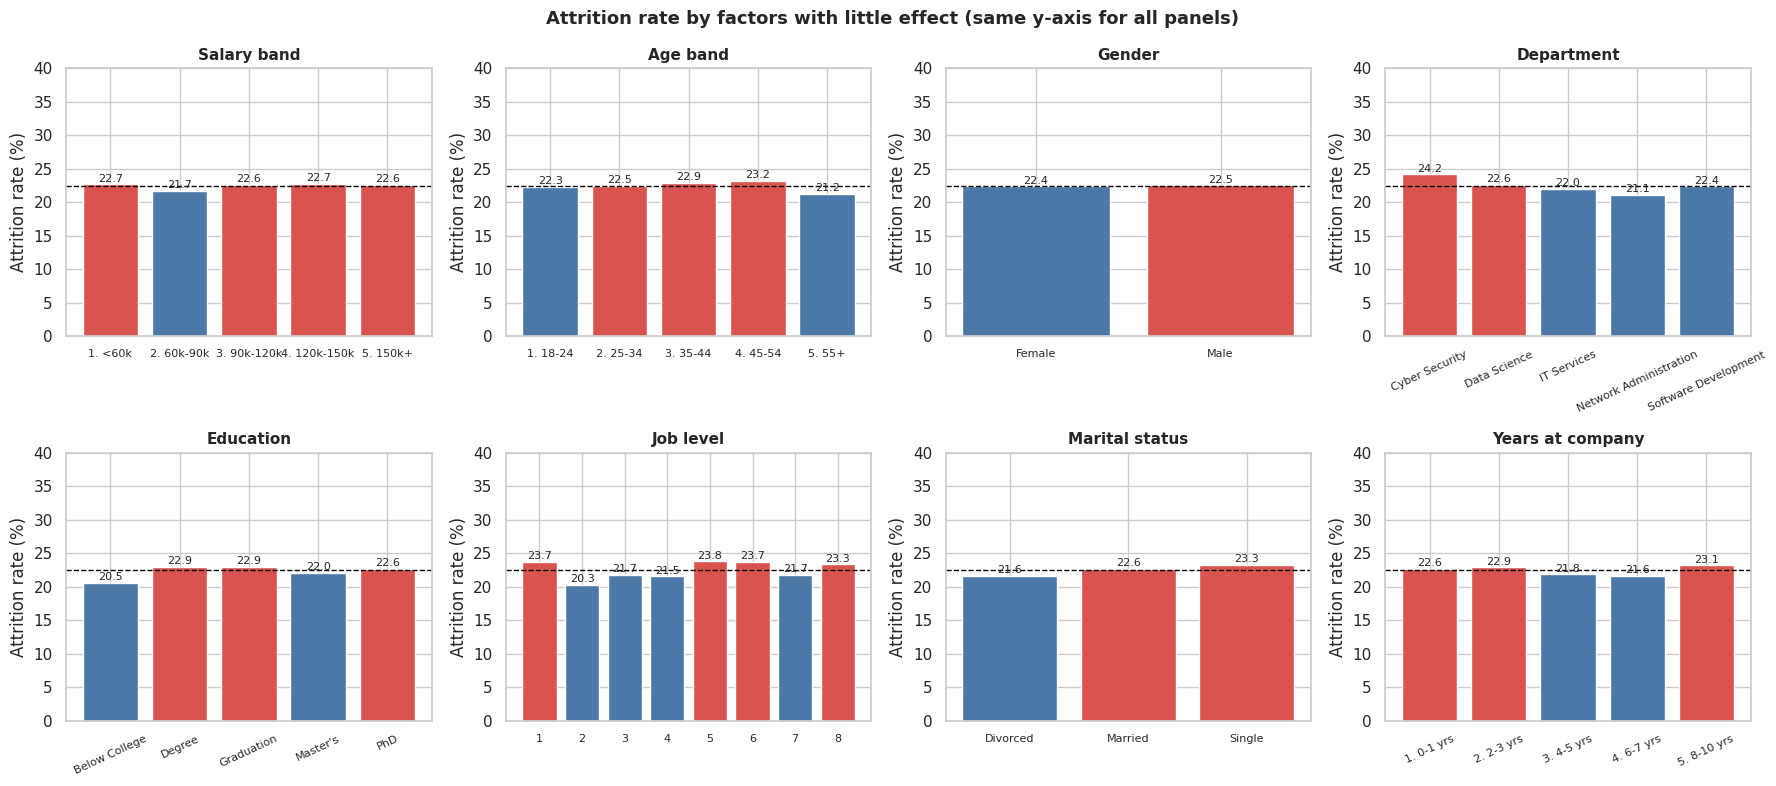

In [6]:
panels = [("salary_band", "Salary band", 0), ("age_band", "Age band", 0), ("gender", "Gender", 0),
          ("department", "Department", 25), ("education", "Education", 25), ("job_level", "Job level", 0),
          ("marital_status", "Marital status", 0), ("tenure_band", "Years at company", 25)]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, (col, title, rot) in zip(axes.flat, panels):
    plot_rate(ax, rate_table(df, col), col, overall, title, rotate=rot)
    ax.set_ylim(0, 40)
fig.suptitle("Attrition rate by factors with little effect (same y-axis for all panels)", fontsize=13, fontweight="bold")
fig.tight_layout()
savefig(fig, "02_attrition_flat_factors")
plt.show()

## 5. Two factors together

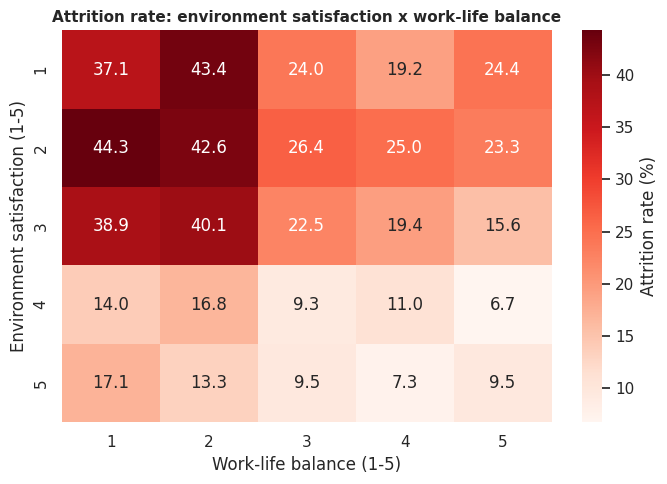

In [7]:
pivot = df.pivot_table(index="environment_satisfaction", columns="work_life_balance",
                       values="attrition_flag", aggfunc="mean") * 100
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(pivot.round(1), annot=True, fmt=".1f", cmap="Reds", cbar_kws={"label": "Attrition rate (%)"}, ax=ax)
ax.set_title("Attrition rate: environment satisfaction x work-life balance", fontsize=11, fontweight="bold")
ax.set_xlabel("Work-life balance (1-5)")
ax.set_ylabel("Environment satisfaction (1-5)")
fig.tight_layout()
savefig(fig, "02_heatmap_environment_vs_work_life")
plt.show()

In [8]:
(df.pivot_table(index="business_travel", columns="overtime", values="attrition_flag", aggfunc="mean") * 100).round(1)

overtime,No,Yes
business_travel,,
No Travel,17.6,21.3
Travel Frequently,32.3,38.9
Travel Rarely,18.0,23.6


## 6. Segment scatter plot

Each point is one **segment** (for example "Overtime: Yes" or "Distance from home: 40+"). The x-axis is the number of employees in the segment, the y-axis is its attrition rate, and the bubble size is the number of leavers. Segments **high on the chart and far to the right** are large groups with high attrition: the best place to act first. Only segments with 300 or more employees are shown.

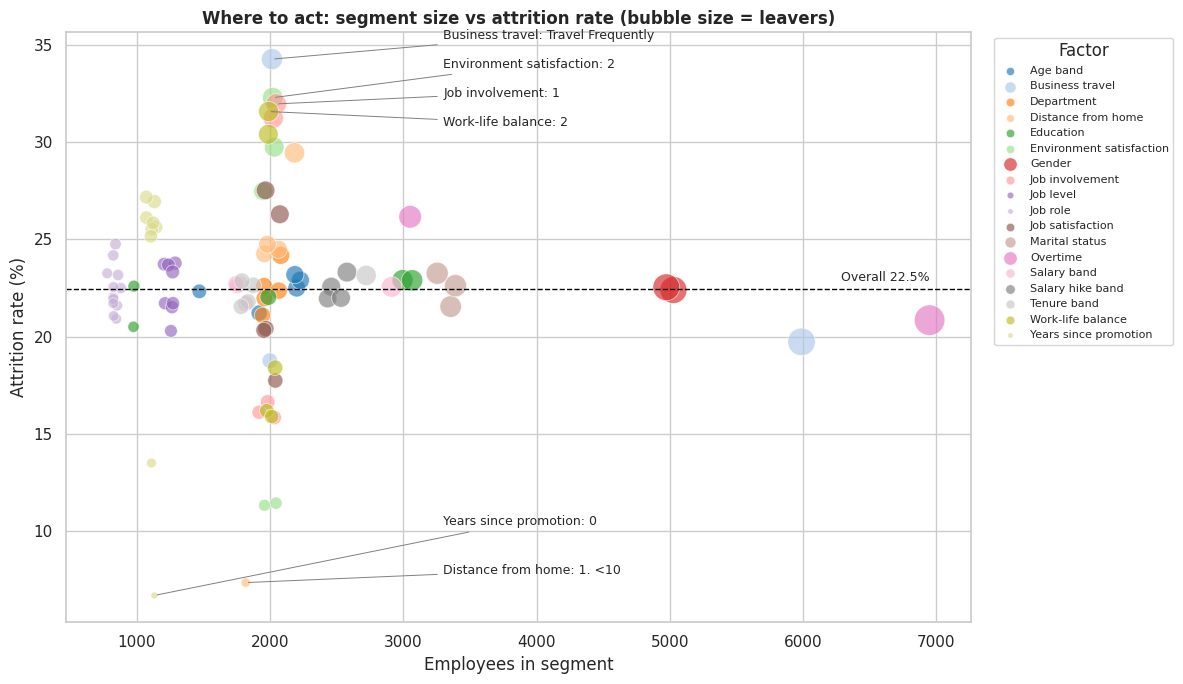

In [9]:
seg = segment_table(df, SEGMENT_FACTORS)
seg = seg[seg["employees"] >= 300].copy()

fig, ax = plt.subplots(figsize=(12, 7))
palette = sns.color_palette("tab20", n_colors=seg["factor"].nunique())
for color, (factor, g) in zip(palette, seg.groupby("factor")):
    ax.scatter(g["employees"], g["attrition_rate_pct"], s=g["leavers"] / 3, alpha=0.65, color=color,
               edgecolor="white", linewidth=0.6, label=factor)
ax.axhline(overall, color="black", linestyle="--", linewidth=1)
ax.text(seg["employees"].max(), overall + 0.4, f"Overall {overall:.1f}%", ha="right", fontsize=9)

top = seg.sort_values("attrition_rate_pct", ascending=False).head(4)
low = seg.sort_values("attrition_rate_pct").head(2)
label_y = list(np.linspace(35.5, 31.0, len(top))) + list(np.linspace(10.5, 8.0, len(low)))
for (_, r), ty in zip(pd.concat([top, low]).iterrows(), label_y):
    ax.annotate(r["label"], xy=(r["employees"], r["attrition_rate_pct"]), xytext=(3300, ty), fontsize=9,
                arrowprops=dict(arrowstyle="-", color="grey", linewidth=0.7), va="center")

ax.set_xlabel("Employees in segment")
ax.set_ylabel("Attrition rate (%)")
ax.set_title("Where to act: segment size vs attrition rate (bubble size = leavers)", fontsize=12, fontweight="bold")
ax.legend(title="Factor", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8, ncol=1, markerscale=0.5)
fig.tight_layout()
savefig(fig, "02_segment_scatter")
plt.show()

In [10]:
cols = ["label", "employees", "leavers", "attrition_rate_pct", "lift", "share_of_leavers_pct"]
display(Markdown("**Ten highest-risk segments (300+ employees)**"))
display(seg.sort_values("attrition_rate_pct", ascending=False)[cols].head(10).reset_index(drop=True))
display(Markdown("**Ten lowest-risk segments (300+ employees)**"))
display(seg.sort_values("attrition_rate_pct")[cols].head(10).reset_index(drop=True))

**Ten highest-risk segments (300+ employees)**

,label,employees,leavers,attrition_rate_pct,lift,share_of_leavers_pct
0,Business travel: Travel Frequently,2014,690,34.26,1.52,30.71
1,Environment satisfaction: 2,2020,652,32.28,1.44,29.02
2,Job involvement: 1,2046,654,31.96,1.42,29.11
3,Work-life balance: 2,1989,628,31.57,1.41,27.95
4,Job involvement: 2,2024,632,31.23,1.39,28.13
5,Work-life balance: 1,1987,604,30.40,1.35,26.88
6,Environment satisfaction: 1,2031,604,29.74,1.32,26.88
7,Distance from home: 5. 40+,2183,643,29.45,1.31,28.62
8,Job satisfaction: 2,1966,541,27.52,1.22,24.08
9,Environment satisfaction: 3,1947,535,27.48,1.22,23.81


**Ten lowest-risk segments (300+ employees)**

,label,employees,leavers,attrition_rate_pct,lift,share_of_leavers_pct
0,Years since promotion: 0,1132,76,6.71,0.30,3.38
1,Distance from home: 1. <10,1817,134,7.37,0.33,5.96
2,Environment satisfaction: 5,1958,222,11.34,0.50,9.88
3,Environment satisfaction: 4,2044,234,11.45,0.51,10.41
4,Years since promotion: 1,1110,150,13.51,0.60,6.68
5,Job involvement: 5,2031,322,15.85,0.71,14.33
6,Work-life balance: 5,2012,320,15.90,0.71,14.24
7,Job involvement: 4,1917,309,16.12,0.72,13.75
8,Work-life balance: 4,1975,320,16.20,0.72,14.24
9,Job involvement: 3,1982,330,16.65,0.74,14.69


## 7. Key takeaways

In [11]:
def pct(mask):
    return df.loc[mask, "attrition_flag"].mean() * 100

def spread(col):
    t = rate_table(df, col)["attrition_rate_pct"]
    return f"{t.min():.1f}% to {t.max():.1f}%"

lines = [
    f"- Overall attrition is **{overall:.2f}%** ({leavers:,} of {len(df):,} employees).",
    f"- **Environment satisfaction** of 3 or lower: **{pct(df.environment_satisfaction <= 3):.1f}%** attrition, against {pct(df.environment_satisfaction >= 4):.1f}% for scores of 4 or 5.",
    f"- **Work-life balance** of 2 or lower: **{pct(df.work_life_balance <= 2):.1f}%**, against {pct(df.work_life_balance >= 3):.1f}% for 3 or higher.",
    f"- **Job involvement** of 2 or lower: **{pct(df.job_involvement <= 2):.1f}%**, against {pct(df.job_involvement >= 3):.1f}% for 3 or higher.",
    f"- **2 or more years since the last promotion**: **{pct(df.years_since_promotion >= 2):.1f}%**, against {pct(df.years_since_promotion < 2):.1f}% for less than 2 years.",
    f"- **Distance from home of 10 or more**: **{pct(df.distance_from_home >= 10):.1f}%**, against {pct(df.distance_from_home < 10):.1f}% for under 10.",
    f"- **Frequent business travel**: **{pct(df.business_travel == 'Travel Frequently'):.1f}%**, against {pct(df.business_travel != 'Travel Frequently'):.1f}% for everyone else.",
    f"- **Overtime**: **{pct(df.overtime == 'Yes'):.1f}%**, against {pct(df.overtime == 'No'):.1f}% without overtime.",
    f"- **Little or no effect:** salary band ({spread('salary_band')}), age band ({spread('age_band')}), gender ({spread('gender')}), department ({spread('department')}), education ({spread('education')}).",
]
display(Markdown("\n".join(lines)))

- Overall attrition is **22.47%** (2,247 of 10,000 employees).
- **Environment satisfaction** of 3 or lower: **29.9%** attrition, against 11.4% for scores of 4 or 5.
- **Work-life balance** of 2 or lower: **31.0%**, against 16.8% for 3 or higher.
- **Job involvement** of 2 or lower: **31.6%**, against 16.2% for 3 or higher.
- **2 or more years since the last promotion**: **26.1%**, against 10.1% for less than 2 years.
- **Distance from home of 10 or more**: **25.8%**, against 7.4% for under 10.
- **Frequent business travel**: **34.3%**, against 19.5% for everyone else.
- **Overtime**: **26.2%**, against 20.9% without overtime.
- **Little or no effect:** salary band (21.7% to 22.7%), age band (21.2% to 23.2%), gender (22.4% to 22.5%), department (21.1% to 24.2%), education (20.5% to 22.9%).